# **Assignment 4. EuroSAT Land Use and Land Cover Classification**#

In this notebook, increasingly complex deep learning models are implementated to identify land use and land cover classifications on the [EuroSAT dataset](https://github.com/phelber/eurosat), a collection of 27,000 Sentinel-2 satellite images consisting of 13 spectral bands and 10 pre-labeled classes (e.g., Highway, AnnualCrop, River, Residential).[1][2]

**[1]** Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification. Patrick Helber, Benjamin Bischke, Andreas Dengel, Damian Borth. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 2019.

**[2]** Introducing EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification. Patrick Helber, Benjamin Bischke, Andreas Dengel. 2018 IEEE International Geoscience and Remote Sensing Symposium, 2018.



## **Part A. Data Preprocessing**

- Mount Google Drive and install the Python package Rasterio that can access to geospatial raster data

- Download data from the Eurosat page: https://github.com/phelber/eurosat

- Split the data into training (50%) and testing sets (50%), stratified on class labels (equal percentage of each class type in train and test sets).

### **Step 1. Install the Python package Rasterio**

In [1]:
# Install Rasterio
!pip install rasterio
!pip install requests
!pip install scikit-image
!pip install tensorflow
!pip install scikit-learn
!pip install pandas

### **Step 2. Import related packages for image processing and deep learning model**

In [2]:
# Packages for image reading and processing
import requests  #A HTTP package for Python
import zipfile  #A zip package (craete, read, write, append a ZIP file) for Python
import io #Python package for text I/O, binary I/O and raw I/O

from PIL import Image #PIL (Python Imaging Library): image processing
from skimage.color import rgb2gray  #Collection of algorithms for image procssing
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import rasterio
from rasterio.plot import show, show_hist

# Tensor processing
import numpy as np
import os
from sklearn.utils import shuffle   # sklearn: machine learning package
from sklearn.preprocessing import LabelBinarizer

# Plotting
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model

# Deep learning modeling
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential,Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input
from tensorflow.keras.optimizers import RMSprop,Adam
from tensorflow.keras.applications import vgg16, resnet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# evaluation metrics
from sklearn.metrics import classification_report
import pandas as pd #pandas: data analysis package

from tensorflow.keras import backend as K
import tensorflow as tf

# 限制 GPU 只動態分配需要的記憶體
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

batch_size=16
epochs=10

2025-11-11 23:58:53.013277: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-11 23:58:53.044212: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-11 23:58:53.526070: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2025-11-11 23:58:54.415357: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.

### **Step 3. Download and read RGB EuroSAT images from URL**


In [4]:
# RGB file URL
url="http://madm.dfki.de/files/sentinel/EuroSAT.zip"

# download zip
r=requests.get(url)
z=zipfile.ZipFile(io.BytesIO(r.content))

# get file names
txtfiles=[]
for file in z.namelist():
  txtfiles.append(file)

# keep only those containing ".jpg"
txtfiles=[x for x in txtfiles if ".jpg" in x]

# read images to numpy array
XImages=np.zeros([len(txtfiles), 64, 64, 3])

i=0
for pic in txtfiles:
  #Image.open() is an image opening function in the PIL module 'Image'
  XImages[i]=np.asarray(Image.open(z.open(pic))).astype('uint8')/255  #normalize image from [0, 255] to [0.0, 1.0]
  i+=1

print("The number of image:", i)
print("The shape of XImages:", XImages.shape)
del r # clear memory
del z

The number of image: 27000
The shape of XImages: (27000, 64, 64, 3)


### **Step 4. Show the downloaded images**

[[[0.21176471 0.29803922 0.35294118]
  [0.21176471 0.29803922 0.35294118]
  [0.18823529 0.2627451  0.32941176]
  ...
  [0.32941176 0.36470588 0.39215686]
  [0.21960784 0.30980392 0.33333333]
  [0.18823529 0.30196078 0.3254902 ]]

 [[0.21960784 0.29019608 0.34509804]
  [0.22352941 0.29411765 0.34901961]
  [0.18823529 0.2627451  0.32156863]
  ...
  [0.31764706 0.36862745 0.4       ]
  [0.21568627 0.31372549 0.33333333]
  [0.18823529 0.30196078 0.3254902 ]]

 [[0.30196078 0.35294118 0.38823529]
  [0.29803922 0.35294118 0.38823529]
  [0.25490196 0.31764706 0.36862745]
  ...
  [0.23137255 0.32156863 0.34509804]
  [0.2        0.30588235 0.33333333]
  [0.19215686 0.30980392 0.34117647]]

 ...

 [[0.21568627 0.30588235 0.32941176]
  [0.21568627 0.30588235 0.32941176]
  [0.22745098 0.31764706 0.34117647]
  ...
  [0.28235294 0.36078431 0.36470588]
  [0.34509804 0.4        0.40392157]
  [0.32156863 0.36862745 0.36862745]]

 [[0.23529412 0.33333333 0.34901961]
  [0.23529412 0.33333333 0.34901961]


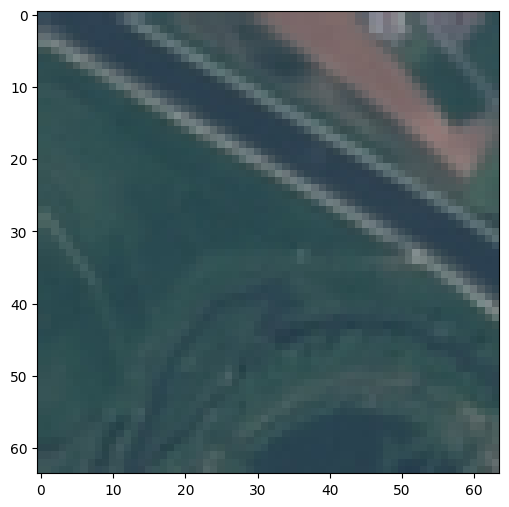

In [5]:
def plot_image(image):
  fig,ax=plt.subplots(figsize=(6,6))
  ax.imshow(image)
  plt.show()

# Call plot_image() to display an image
print(XImages[0])
plot_image(XImages[0])

### **Step 5. Get image lables**

In [6]:
# Get labels in numpy array as strings
# Example: Extract "River" from "2750/River/River_479.jpg"
labs=np.empty(len(txtfiles), dtype='S20')
i=0
for label in txtfiles:
  labs[i]=label.split('/')[1]
  i+=1

print(labs)
print(labs.shape)


'''
What does this b character in front of the string mean?

Ans. Python 3.x makes a clear distinction between the types:
-- str = '...'
-- bytes = b'...'
'''

# Change them to integers in alphabetical order

# unique()returns the sorted unique elements of an array;
# return_inverse: if true, return the indices of the unique array that can be used to reconstruct array
label_names,yLabels=np.unique(labs, return_inverse=True)

print("the shape of the label_names:", label_names.shape)
print("label_names:", label_names)
print()
print("the shape of the yLables:", yLabels.shape)
print()

label_Dict=dict(zip(np.unique(yLabels), label_names)) #create a dict: (yLabels, label_names)
print("label_Dict:",label_Dict)
print("\n")
np.array(np.unique(yLabels, return_counts=True)).T

[b'River' b'River' b'River' ... b'PermanentCrop' b'PermanentCrop'
 b'PermanentCrop']
(27000,)
the shape of the label_names: (10,)
label_names: [b'AnnualCrop' b'Forest' b'HerbaceousVegetation' b'Highway' b'Industrial'
 b'Pasture' b'PermanentCrop' b'Residential' b'River' b'SeaLake']

the shape of the yLables: (27000,)

label_Dict: {0: b'AnnualCrop', 1: b'Forest', 2: b'HerbaceousVegetation', 3: b'Highway', 4: b'Industrial', 5: b'Pasture', 6: b'PermanentCrop', 7: b'Residential', 8: b'River', 9: b'SeaLake'}




array([[   0, 3000],
       [   1, 3000],
       [   2, 3000],
       [   3, 2500],
       [   4, 2500],
       [   5, 2000],
       [   6, 2500],
       [   7, 3000],
       [   8, 2500],
       [   9, 3000]])

### **Step 6. Show the processed images and labels**

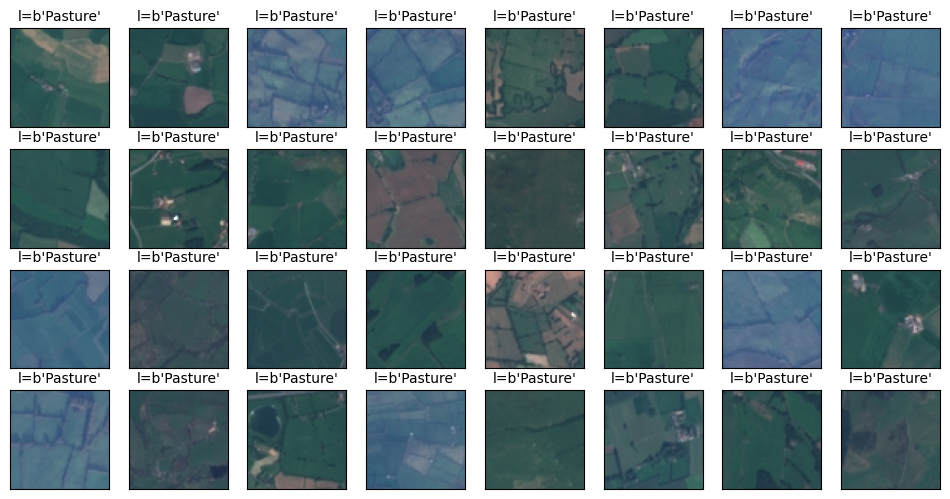

In [7]:
# Test that the labels and images read in properly
def plot_multiimages(images,labels,prediction,idx,num=32):
  fig,ax=plt.subplots(4,8,figsize=(12,6))
  if num>32:num=32 # if the number of images > 32，then set to 32 to avoid errors
  for i in range(0,num):
    ax=plt.subplot(4,8,1+i) # Build 4x8 subgraphs
    ax.imshow(images[idx],cmap='binary')
    if len(prediction)>0:
      title="l={},p={}".format(str(label_names[labels[idx]]),str(prediction[idx]))
    else:
      title="l={}".format(str(label_names[labels[idx]]))
    ax.set_title(title,fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    idx+=1 # read the next image
  plt.show()

plot_multiimages(XImages,yLabels,[],18000,32)

### **Step 7. Shuffle the datasets and balance the labels**

In [8]:
# find the smallest class
smallest_class=np.argmin(np.bincount(yLabels))
print("The class index of the smallest class:",smallest_class, label_names[smallest_class])

# number of classes
num_classes=len(np.array(np.unique(yLabels)))
# observations in smallest class
smallest_class_obs=np.where(yLabels==smallest_class)[0]

# Get 2000 observations from each class
indBal=np.empty(0, dtype=int)
for i in range(num_classes):
  indTemp=shuffle(np.where(yLabels==i)[0], random_state=42)[0:smallest_class_obs.shape[0]]
  indBal=np.concatenate([indBal, indTemp])

# shuffle the balanced index
indBal=shuffle(indBal, random_state=42)

yBal=yLabels[indBal]
XBal=XImages[indBal]

print(yBal.shape)
print(XBal.shape)

The class index of the smallest class: 5 b'Pasture'
(20000,)
(20000, 64, 64, 3)


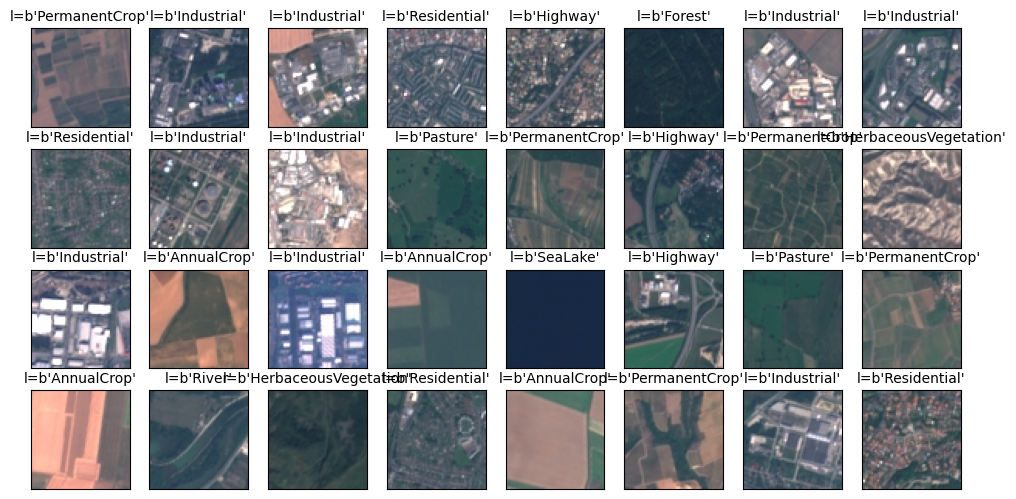

In [9]:
# first line uses balanced labels
# second line uses original imbalanced labels
X_train,X_test,y_train,y_test=train_test_split(XImages, yLabels, stratify=yLabels, train_size=0.5, random_state=42)

# Test that the labels and images are still matched up properly
plot_multiimages(X_train,y_train,[],300,32)

In [10]:
# class distribution for yTrain
np.array(np.unique(y_train, return_counts=True)).T

# class distribution for yTest
np.array(np.unique(y_test, return_counts=True)).T

# convert class vectors to binary class matrices
y_train=tensorflow.keras.utils.to_categorical(y_train, num_classes)
y_test=tensorflow.keras.utils.to_categorical(y_test, num_classes)

### **Part B. Model 1**

- Convert each RBG image to grayscale and flatten the images into a data matrix (n x p: n = #samples, p = #pixels in each image)

- Implement a first deep learning model `M1` using a fully connected network with a single dense layer.

- **Classification accuracy on the test data.** 24.75%

This model does not include any spatial information (i.e., pixels don't have any information about neighboring pixels).

In [10]:
# Initialize grayscale arrays
X_train_BW=np.zeros([X_train.shape[0], X_train.shape[1], X_train.shape[2]])

X_test_BW=np.zeros([X_test.shape[0], X_test.shape[1], X_test.shape[2]])

# convert RGB arrays to grayscale
for i in range(X_train.shape[0]):
  X_train_BW[i]=rgb2gray(X_train[i])
  X_test_BW[i]=rgb2gray(X_test[i])

# flatten grayscale arrays
X_train_BW=X_train_BW.reshape(X_train_BW.shape[0], X_train_BW.shape[1]*X_train_BW.shape[2])

X_test_BW=X_test_BW.reshape(X_test_BW.shape[0], X_test_BW.shape[1]*X_test_BW.shape[2])

print("X_train_BW shape:" + str(X_train_BW.shape))
print("X_test_BW shape:" + str(X_test_BW.shape))
print("y_train shape:" + str(y_train.shape))
print("y_test shape:" + str(y_test.shape))

X_train_BW shape:(13500, 4096)
X_test_BW shape:(13500, 4096)
y_train shape:(13500, 10)
y_test shape:(13500, 10)


Implement first deep learning model

In [11]:
M1=Sequential()
M1.add(Dense(num_classes, activation='softmax', input_shape=(4096,)))
M1.summary()

M1.compile(loss='categorical_crossentropy',optimizer=Adam(),metrics=['accuracy'])

train_history_M1=M1.fit(X_train_BW, y_train, batch_size=batch_size, epochs=epochs, verbose=1,
                validation_data=(X_test_BW,y_test))

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 10)                40970     
                                                                 
Total params: 40970 (160.04 KB)
Trainable params: 40970 (160.04 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


2025-11-11 20:42:37.077120: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-11-11 20:42:37.077346: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-11-11 20:42:37.077441: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

Epoch 1/10


2025-11-11 20:42:37.863606: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:606] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-11-11 20:42:37.880963: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x7202980568c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-11 20:42:37.880984: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2025-11-11 20:42:37.885507: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:255] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-11 20:42:37.896349: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
2025-11-11 20:42:37.984680: I ./tensorflow/compiler/jit/device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifeti

844/844 [==============================] - 3s 3ms/step - loss: 2.4475 - accuracy: 0.1435 - val_loss: 2.3711 - val_accuracy: 0.1450
Epoch 2/10
844/844 [==============================] - 2s 2ms/step - loss: 2.3585 - accuracy: 0.1733 - val_loss: 2.4222 - val_accuracy: 0.1379
Epoch 3/10
844/844 [==============================] - 2s 2ms/step - loss: 2.3185 - accuracy: 0.1921 - val_loss: 2.3735 - val_accuracy: 0.2534
Epoch 4/10
844/844 [==============================] - 2s 2ms/step - loss: 2.2921 - accuracy: 0.2085 - val_loss: 2.3130 - val_accuracy: 0.1665
Epoch 5/10
844/844 [==============================] - 2s 2ms/step - loss: 2.2631 - accuracy: 0.2197 - val_loss: 2.4037 - val_accuracy: 0.2490
Epoch 6/10
844/844 [==============================] - 2s 2ms/step - loss: 2.2156 - accuracy: 0.2330 - val_loss: 2.2724 - val_accuracy: 0.1739
Epoch 7/10
844/844 [==============================] - 2s 2ms/step - loss: 2.2044 - accuracy: 0.2407 - val_loss: 2.2153 - val_accuracy: 0.2252
Epoch 8/10
844/84

Test loss: 2.2182159423828125
Test accuracy: 0.24970370531082153


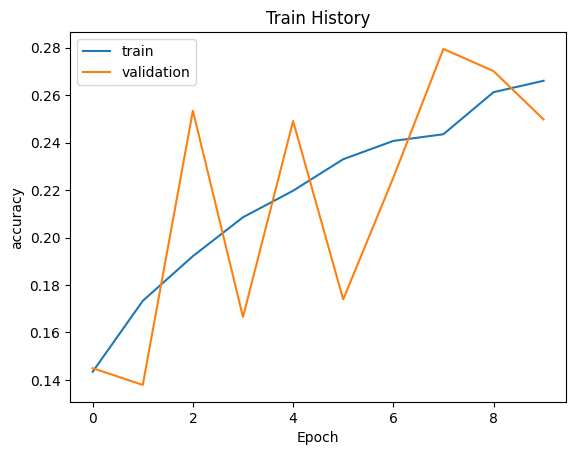

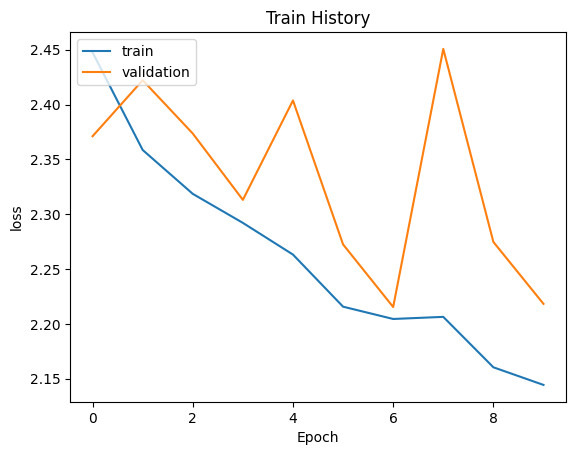

In [12]:
score=M1.evaluate(X_test_BW, y_test, verbose=0)
print('Test loss:',score[0])
print('Test accuracy:',score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M1,'accuracy','val_accuracy')
show_train_history(train_history_M1,'loss','val_loss')

### **Part B. Model 2**

- Implement a second deep learning model `M2` adding an additional dense layer to the previous model.

- **Classification accuracy on the test data.** 24.39%

In [13]:
M2=Sequential()
M2.add(Dense(256, activation='relu', input_shape=(4096,)))
M2.add(Dense(num_classes, activation='softmax'))

M2.summary()

M2.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
train_history_M2=M2.fit(X_train_BW, y_train, batch_size=batch_size, epochs=epochs,
               verbose=1, validation_data=(X_test_BW,y_test))

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 256)               1048832   
                                                                 
 dense_2 (Dense)             (None, 10)                2570      
                                                                 
Total params: 1051402 (4.01 MB)
Trainable params: 1051402 (4.01 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/10
844/844 [==============================] - 3s 3ms/step - loss: 2.2693 - accuracy: 0.1384 - val_loss: 2.1816 - val_accuracy: 0.1459
Epoch 2/10
844/844 [==============================] - 2s 2ms/step - loss: 2.1601 - accuracy: 0.2022 - val_loss: 2.1834 - val_accuracy: 0.2139
Epoch 3/10
844/844 [==============================] - 2s 2ms/step - loss: 2.1115 - accuracy: 0.2354 - val_loss: 2.0876 - val_acc

Test loss: 1.937667965888977
Test accuracy: 0.2768888771533966


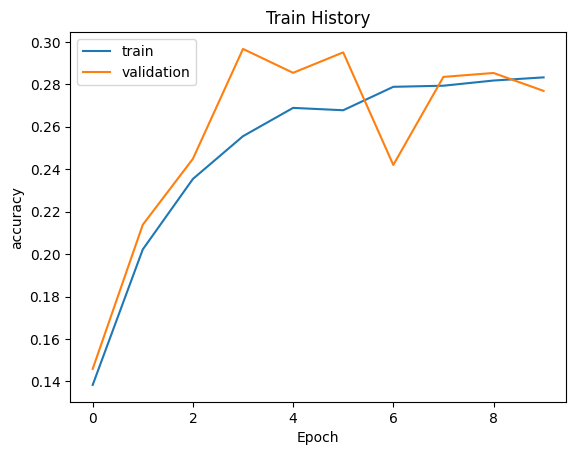

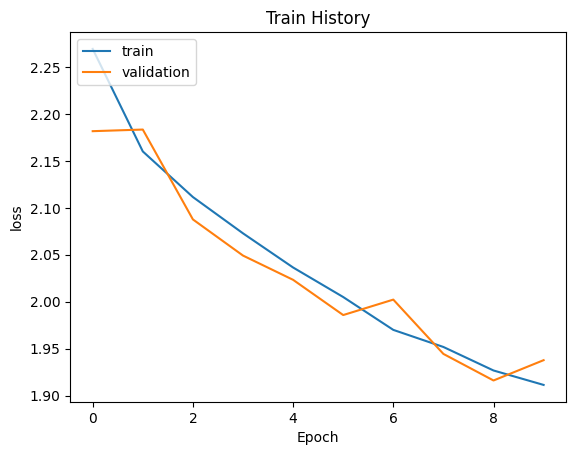

In [14]:
score=M2.evaluate(X_test_BW, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M2,'accuracy','val_accuracy')
show_train_history(train_history_M2,'loss','val_loss')

### **Part B. Model 3**

- Implement a third deep learning model `M3` adding two additional dense layers as well as drop-out layers to the previous model.

- **Classification accuracy on the test data.** 11.1%
- **Compare against previous models. Which model was the "best"? Why?** Of the first three models, `M2` was the best. It had a higher accuracy on the test data, and based on the plots showing training/testing loss and accuracy, it fit the data better than either Models M1 or M3, which both showed large fluctuations in the testing loss and accuracy.

In [15]:
M3=Sequential()
M3.add(Dense(256, activation='relu', input_shape=(4096,)))
M3.add(Dropout(0.2))
M3.add(Dense(256, activation='relu'))
M3.add(Dropout(0.2))
M3.add(Dense(256, activation='relu'))
M3.add(Dropout(0.2))
M3.add(Dense(num_classes, activation='softmax'))

M3.summary()

M3.compile(loss='categorical_crossentropy',optimizer=Adam(),metrics=['accuracy'])

train_history_M3=M3.fit(X_train_BW, y_train, batch_size=batch_size, epochs=epochs,
               verbose=1, validation_data=(X_test_BW,y_test))

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 256)               1048832   
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_4 (Dense)             (None, 256)               65792     
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_5 (Dense)             (None, 256)               65792     
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_6 (Dense)             (None, 10)               

Test loss: 2.586219549179077
Test accuracy: 0.15303704142570496


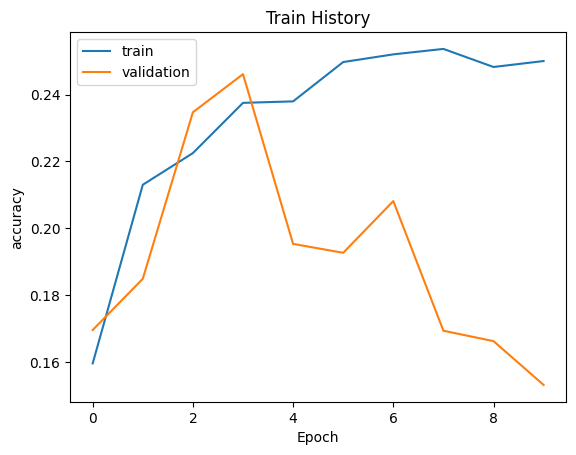

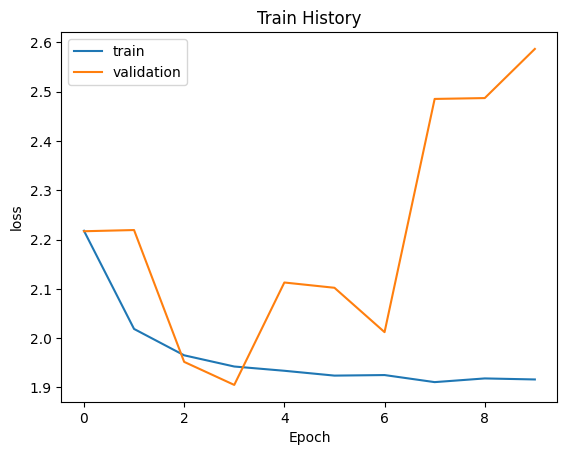

In [16]:
score=M3.evaluate(X_test_BW, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M3,'accuracy','val_accuracy')
show_train_history(train_history_M3,'loss','val_loss')

### **Part B. Model 4**

- Using RGB images (without vectorizing them), implement a fourth model `M4` that includes the following layers: Conv2D, MaxPooling2D, Dropout, Flatten, Dense.

- **Classification accuracy on the test data.** 72.99%
- **Compare against previous models. Which model was the "best"? Why?** Model `M4` is clearly the best so far, with a testing accuracy of 72.99%. The inclusion of the convolutional and maxpooling layers added a spatial component to the model, boosting the predictive power significantly. Based on the divergence of the training/testing loss and accuracy plots, the model started overfitting the training data after 10 or so epochs.

In [17]:
input_shape=X_train.shape[1:]
M4=Sequential()
M4.add(Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=input_shape))
M4.add(Conv2D(64, (3,3), activation='relu'))
M4.add(MaxPooling2D(pool_size=(2,2)))
M4.add(Dropout(0.2))
M4.add(Flatten())
M4.add(Dense(256, activation='relu'))
M4.add(Dropout(0.2))
M4.add(Dense(num_classes, activation='softmax'))

M4.summary()

M4.compile(loss='categorical_crossentropy',optimizer=Adam(),metrics=['accuracy'])

train_history_M4=M4.fit(X_train,y_train,batch_size=batch_size,epochs=epochs,
              verbose=1,validation_data=(X_test,y_test))

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 32)        896       
                                                                 
 conv2d_1 (Conv2D)           (None, 60, 60, 64)        18496     
                                                                 
 max_pooling2d (MaxPooling2  (None, 30, 30, 64)        0         
 D)                                                              
                                                                 
 dropout_3 (Dropout)         (None, 30, 30, 64)        0         
                                                                 
 flatten (Flatten)           (None, 57600)             0         
                                                                 
 dense_7 (Dense)             (None, 256)               14745856  
                                                      

2025-11-11 20:43:46.401782: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:954] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape insequential_3/dropout_3/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


844/844 [==============================] - 12s 12ms/step - loss: 1.3153 - accuracy: 0.5158 - val_loss: 0.8610 - val_accuracy: 0.7004
Epoch 2/10
844/844 [==============================] - 9s 11ms/step - loss: 0.8054 - accuracy: 0.7139 - val_loss: 0.7071 - val_accuracy: 0.7561
Epoch 3/10
844/844 [==============================] - 9s 11ms/step - loss: 0.5865 - accuracy: 0.7894 - val_loss: 0.7072 - val_accuracy: 0.7550
Epoch 4/10
844/844 [==============================] - 9s 11ms/step - loss: 0.4467 - accuracy: 0.8456 - val_loss: 0.6397 - val_accuracy: 0.7834
Epoch 5/10
844/844 [==============================] - 9s 11ms/step - loss: 0.3524 - accuracy: 0.8777 - val_loss: 0.6497 - val_accuracy: 0.7920
Epoch 6/10
844/844 [==============================] - 9s 11ms/step - loss: 0.2498 - accuracy: 0.9148 - val_loss: 0.9458 - val_accuracy: 0.7458
Epoch 7/10
844/844 [==============================] - 9s 11ms/step - loss: 0.2080 - accuracy: 0.9327 - val_loss: 0.8584 - val_accuracy: 0.7830
Epoch 8/1

Test loss: 0.9668474197387695
Test accuracy: 0.7883703708648682


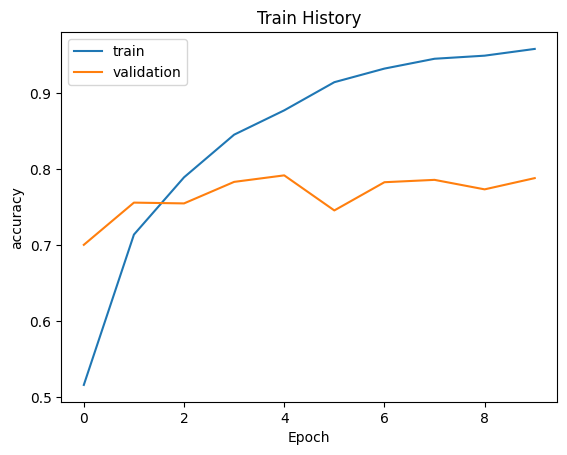

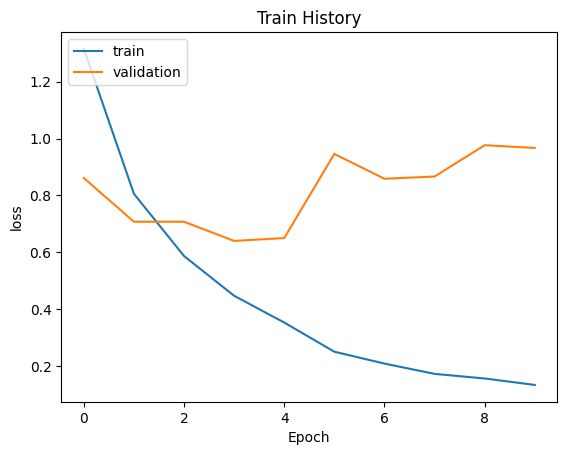

In [18]:
score=M4.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M4,'accuracy','val_accuracy')
show_train_history(train_history_M4,'loss','val_loss')

### **Models 5-8**

- Using RGB images (without vectorizing them), implement a deep learning model targeting accuracy that will outperform all previous models.

- **Describe the model you built, and why you chose it.** I built five more models
  - _M5:_ A model with 4 convolution-maxpooling layer pairs before a dropout layer and a dense layer. I added the additional convolutions to try to extract larger features in each image.
  - _M6:_ This model is M5, but I replaced the convolutional layers with the convolutional base of the `VGG16` model instead.[3] I ran this once with the pre-loaded weights, and I ran it again with some of the convolutional layers in VGG16 unfrozen and a lower learning rate to extract some of the lower level features from the EuroSAT images. Unfreezing the weights improved the model by about 1.6 percentage points. I created this model to see (1) the effect transfer learning would have on my accuracy and (2) the improvements I could get from fine-tuning the pre-loaded weights.
  - _M7:_ This model is the same as M6 but uses training data that has been augmented through random shearing, rotating, and flipping. I wanted to see if this would improve the overfitting I'd been seeing in some of my models.
  - _M8:_ It has the same layers and data augmentation as M7, but it also includes two callbacks: `EarlyStopping` to reduce overfitting and keep the weights from the epoch with the lowest validation loss and `ReduceLROnPlateau` to decay the learning rate as validation loss improvements slow.

- **Classification accuracy on the test data.**
  - _M5:_ 88.10%
  - _M6:_ 93.00% with pre-loaded VGG16 weights
  - _M7:_ 94.32%
  - _M8:_ 96.94%

- **Compare against previous models. Which model was the "best"? Why?** M8, which uses VGG16's convolutional base, augmented data, and callbacks, had the best performance. In terms of accuracy, it correctly classified 94.5% of the test set. Based on the training/testing accuracy and loss plots, the two models with callbacks clearly performed better from an overfitting perspective. The decay in the learning rate also helped the model make marginal improvements in validation loss more quickly than previous models. Lastly, EarlyStopping reduced the training time and allowed me to retain the weights from the epoch with the lowest validation loss.

- **What are the two classes with the highest labeling error? Explain using data and showing mis-classified examples.** The highest errors were in the SeaLake and AnnualCrop images, which both had accuracies in the low 90's, well below the other categories. As shown in the examples, they were most often confused with Forest and PermanentCrop/Pasture, respectively.

**[3]** Very Deep Convolutional Networks for Large-Scale Image Recognition
K. Simonyan, A. Zisserman
arXiv:1409.1556

### **Part B. Model 5**

In [19]:
input_shape=X_train.shape[1:]
M5 = Sequential()
M5.add(Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=input_shape))
M5.add(MaxPooling2D(pool_size=(2,2)))
M5.add(Conv2D(64, (3,3), activation='relu'))
M5.add(MaxPooling2D(pool_size=(2,2)))
M5.add(Conv2D(128, (3,3), activation='relu'))
M5.add(MaxPooling2D(pool_size=(2,2)))
M5.add(Conv2D(256, (3,3), activation='relu'))
M5.add(MaxPooling2D(pool_size=(2,2)))
M5.add(Flatten())
M5.add(Dropout(0.5))
M5.add(Dense(512, activation='relu'))
# M5.add(Dropout(0.2))
M5.add(Dense(num_classes, activation='softmax'))

M5.summary()

M5.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

train_history_M5=M5.fit(X_train, y_train, batch_size=batch_size, epochs=epochs,
              verbose=1, validation_data=(X_test,y_test))

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 62, 62, 32)        896       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 31, 31, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 29, 29, 64)        18496     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 14, 14, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 12, 12, 128)       73856     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 6, 6, 128)        

Test loss: 0.49587464332580566
Test accuracy: 0.8301481604576111


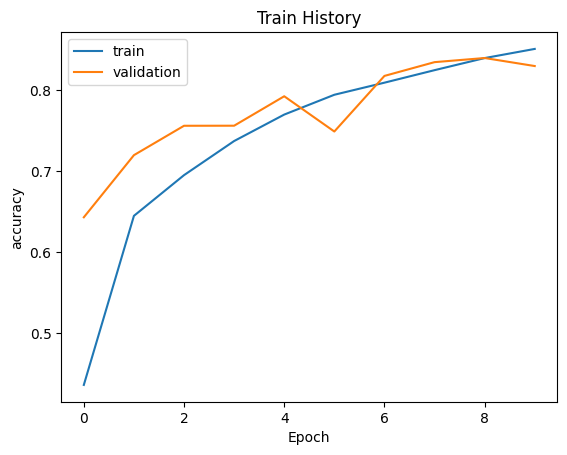

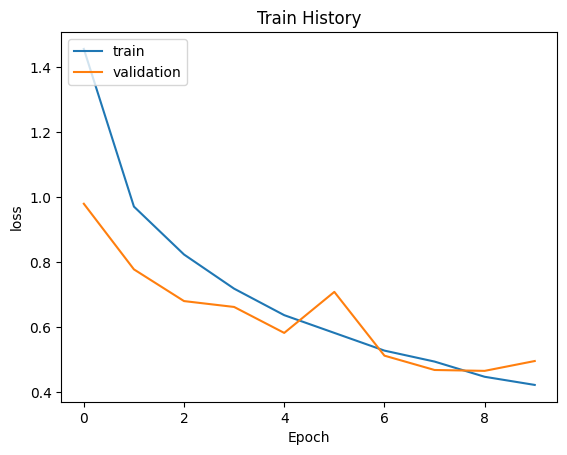

In [20]:
score=M5.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M5,'accuracy','val_accuracy')
show_train_history(train_history_M5,'loss','val_loss')

### **Part B. Model 6:** Use `VGG16` convolutional base for Transfer Learning

In [11]:
input_shape=X_train.shape[1:]
conv_base=vgg16.VGG16(include_top=False,input_shape=input_shape)
conv_base.summary()

len(conv_base.trainable_weights)

2025-11-11 21:11:49.043955: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-11-11 21:11:49.044170: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-11-11 21:11:49.044260: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0     

26

In [12]:
# freeze the weights
for layer in conv_base.layers:
  layer.trainable=False

len(conv_base.trainable_weights)

0

In [13]:
input_shape=X_train.shape[1:]
M6=Sequential()

M6.add(Input(shape=input_shape))
M6.add(conv_base)

M6.add(Flatten())
M6.add(Dropout(0.5))
M6.add(Dense(512, activation='relu'))
M6.add(Dense(num_classes, activation='softmax'))

M6.summary()
conv_base.summary()

M6.compile(loss='categorical_crossentropy',optimizer=Adam(),metrics=['accuracy'])
train_history_M6=M6.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, verbose=1, validation_data=(X_test, y_test))

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 2, 2, 512)         14714688  
                                                                 
 flatten (Flatten)           (None, 2048)              0         
                                                                 
 dropout (Dropout)           (None, 2048)              0         
                                                                 
 dense (Dense)               (None, 512)               1049088   
                                                                 
 dense_1 (Dense)             (None, 10)                5130      
                                                                 
Total params: 15768906 (60.15 MB)
Trainable params: 1054218 (4.02 MB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________
Model: "vg

2025-11-11 21:11:55.851692: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
2025-11-11 21:11:56.109673: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:606] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-11-11 21:11:56.130001: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x26aa1c50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-11 21:11:56.130029: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2025-11-11 21:11:56.133582: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:255] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-11 21:11:56.213885: I ./tensorflow/compiler/jit/device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime o

844/844 [==============================] - 19s 22ms/step - loss: 0.8747 - accuracy: 0.6842 - val_loss: 0.6786 - val_accuracy: 0.7519
Epoch 2/10
844/844 [==============================] - 17s 20ms/step - loss: 0.6612 - accuracy: 0.7661 - val_loss: 0.5383 - val_accuracy: 0.8014
Epoch 3/10
844/844 [==============================] - 17s 21ms/step - loss: 0.6106 - accuracy: 0.7853 - val_loss: 0.5274 - val_accuracy: 0.8136
Epoch 4/10
844/844 [==============================] - 17s 21ms/step - loss: 0.5741 - accuracy: 0.7986 - val_loss: 0.4868 - val_accuracy: 0.8276
Epoch 5/10
844/844 [==============================] - 18s 21ms/step - loss: 0.5414 - accuracy: 0.8079 - val_loss: 0.5035 - val_accuracy: 0.8227
Epoch 6/10
844/844 [==============================] - 18s 21ms/step - loss: 0.5230 - accuracy: 0.8137 - val_loss: 0.4801 - val_accuracy: 0.8312
Epoch 7/10
844/844 [==============================] - 17s 21ms/step - loss: 0.5037 - accuracy: 0.8204 - val_loss: 0.4557 - val_accuracy: 0.8407
Epo

Test loss: 0.47330719232559204
Test accuracy: 0.8338518738746643


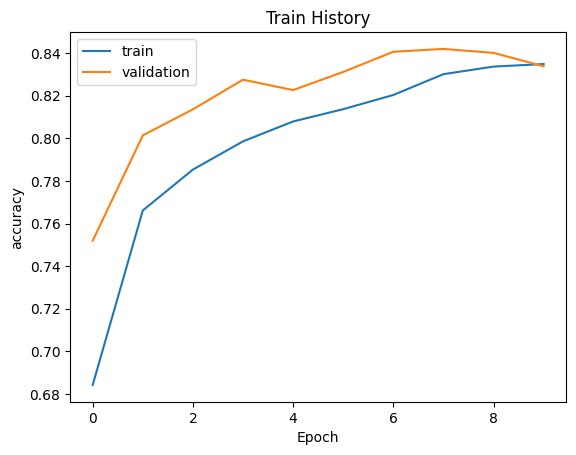

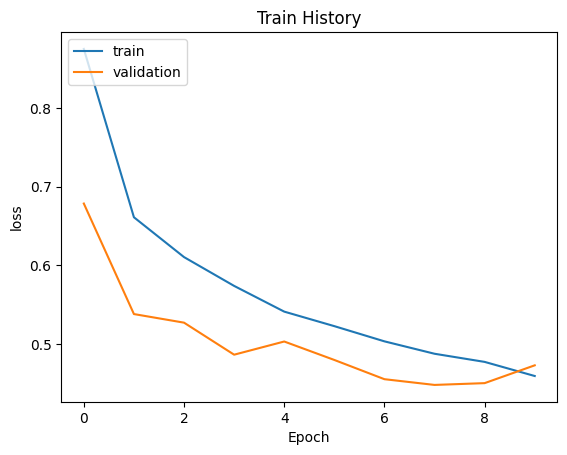

In [14]:
score=M6.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M6,'accuracy','val_accuracy')
show_train_history(train_history_M6,'loss','val_loss')

**Model 6 (Part II):** Unfreeze some layers in the convolutional base

In [15]:
# how many layers are trainable in the VGG16 model?
len(conv_base.trainable_weights)

# unfreeze the latter 2/3ds of the base
for layer in conv_base.layers[7:]:
  layer.trainable = True

len(conv_base.trainable_weights)

18

In [16]:
# set a lower learning rate to minimize magnitude of changes to weights
M6.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=1e-4), metrics=['accuracy'])

train_history_M6=M6.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, verbose=1, validation_data=(X_test, y_test))

Epoch 1/10
844/844 [==============================] - 32s 34ms/step - loss: 0.7783 - accuracy: 0.7379 - val_loss: 0.5613 - val_accuracy: 0.8123
Epoch 2/10
844/844 [==============================] - 28s 33ms/step - loss: 0.3521 - accuracy: 0.8919 - val_loss: 0.2678 - val_accuracy: 0.9104
Epoch 3/10
844/844 [==============================] - 28s 33ms/step - loss: 0.2810 - accuracy: 0.9166 - val_loss: 0.2031 - val_accuracy: 0.9348
Epoch 4/10
844/844 [==============================] - 28s 33ms/step - loss: 0.2114 - accuracy: 0.9359 - val_loss: 0.2989 - val_accuracy: 0.9036
Epoch 5/10
844/844 [==============================] - 28s 33ms/step - loss: 0.1869 - accuracy: 0.9433 - val_loss: 0.2502 - val_accuracy: 0.9216
Epoch 6/10
844/844 [==============================] - 28s 33ms/step - loss: 0.1694 - accuracy: 0.9472 - val_loss: 0.1925 - val_accuracy: 0.9412
Epoch 7/10
844/844 [==============================] - 28s 33ms/step - loss: 0.1354 - accuracy: 0.9587 - val_loss: 0.3380 - val_accuracy:

Test loss: 0.2132372111082077
Test accuracy: 0.9366666674613953


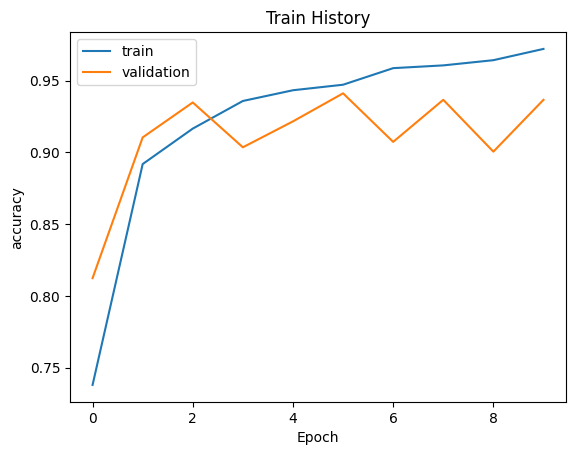

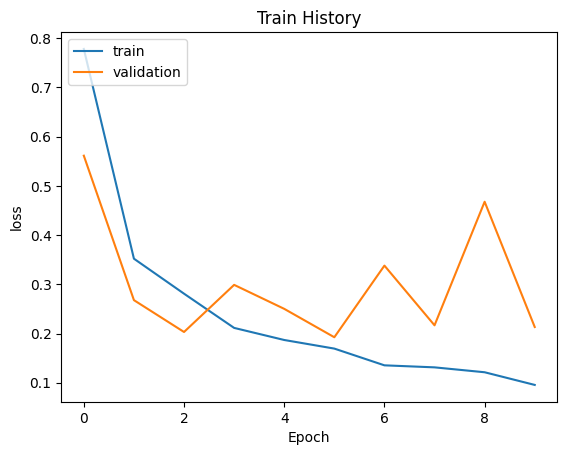

In [17]:
score=M6.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M6,'accuracy','val_accuracy')
show_train_history(train_history_M6,'loss','val_loss')

### **Part B. Model 7:** Model 6 (all trainable)+Data Augmentation

In [18]:
input_shape=X_train.shape[1:]
M7=Sequential()

conv_base=vgg16.VGG16(include_top=False, input_shape=input_shape)

M7.add(conv_base)

M7.add(Flatten())
M7.add(Dropout(0.5))
M7.add(Dense(512,activation='relu'))
M7.add(Dense(num_classes,activation='softmax'))

M7.compile(loss='categorical_crossentropy',optimizer=Adam(learning_rate=1e-4),metrics=['accuracy'])

for layer in conv_base.layers[7:]:
  layer.trainable = True

In [19]:
train_datagen=ImageDataGenerator(horizontal_flip=True, vertical_flip=True)
test_datagen=ImageDataGenerator()

train_generator=train_datagen.flow(X_train, y_train, batch_size=batch_size, seed=42)
test_generator=test_datagen.flow(X_test, y_test, batch_size=batch_size, seed=42)

train_history_M7=M7.fit(train_generator,steps_per_epoch=len(X_train)//batch_size, epochs=epochs,
            validation_data=test_generator,validation_steps=len(X_test)//batch_size)

Epoch 1/10
843/843 [==============================] - 37s 40ms/step - loss: 0.9711 - accuracy: 0.6582 - val_loss: 0.4292 - val_accuracy: 0.8626
Epoch 2/10
843/843 [==============================] - 33s 39ms/step - loss: 0.3989 - accuracy: 0.8779 - val_loss: 0.2478 - val_accuracy: 0.9290
Epoch 3/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2712 - accuracy: 0.9188 - val_loss: 0.1928 - val_accuracy: 0.9480
Epoch 4/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2201 - accuracy: 0.9350 - val_loss: 0.2037 - val_accuracy: 0.9369
Epoch 5/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2151 - accuracy: 0.9379 - val_loss: 0.2449 - val_accuracy: 0.9280
Epoch 6/10
843/843 [==============================] - 33s 39ms/step - loss: 0.1887 - accuracy: 0.9428 - val_loss: 0.2503 - val_accuracy: 0.9233
Epoch 7/10
843/843 [==============================] - 33s 39ms/step - loss: 0.1539 - accuracy: 0.9548 - val_loss: 0.1563 - val_accuracy:

Test loss: 0.18806542456150055
Test accuracy: 0.9437037110328674


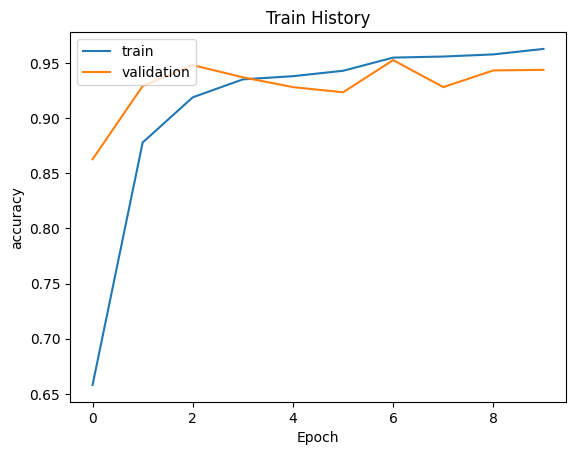

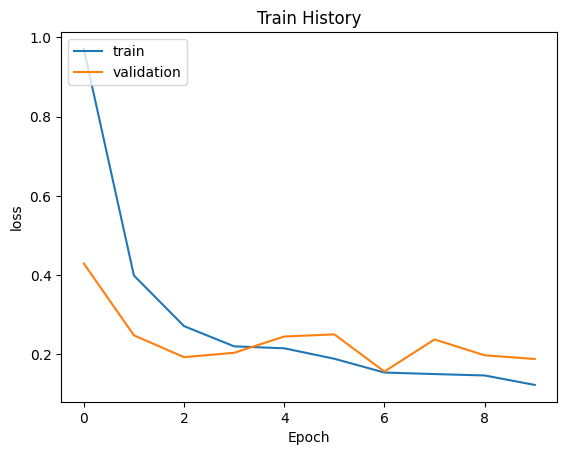

In [20]:
score=M7.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M7,'accuracy','val_accuracy')
show_train_history(train_history_M7,'loss','val_loss')

### **Part B. Model 8:** Try M7 again, but add `EarlyStopping()` and `ReduceLROnPlateau()` (Model 6+Data Augmentation+EarlyStopping+ReduceLRoNpLATEAU)

In [21]:
early_stop=tensorflow.keras.callbacks.EarlyStopping(monitor='val_loss', # what is the metric to measure
                          patience=15, # how many epochs to continue running the model after seeing an increase in val_loss
                          restore_best_weights=True) # update the model with the best-seen weights?

reduce_LR=tensorflow.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                          factor=0.1,
                          patience=5) # to make sure early_stop is what stops the model

callback_list=[reduce_LR, early_stop]

In [22]:
# print learning rate each epoch to see if reduce_LR is working as expected
# https://stackoverflow.com/questions/48198031/keras-add-variables-to-progress-bar/48206009#48206009
def get_lr_metric(optimizer):
  def lr(y_true, y_pred):
    return optimizer.learning_rate
  return lr

optimizer=Adam(learning_rate=1e-4)
lr_metric=get_lr_metric(optimizer)

In [23]:
M8=Sequential()

input_shape=X_train.shape[1:]
conv_base=vgg16.VGG16(include_top=False, input_shape=input_shape)

M8.add(conv_base)

M8.add(Flatten())
M8.add(Dropout(0.5))
M8.add(Dense(512, activation='relu'))
M8.add(Dense(num_classes, activation='softmax'))

M8.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy', lr_metric])

for layer in conv_base.layers[7:]:
  layer.trainable = True

train_datagen=ImageDataGenerator(horizontal_flip=True, vertical_flip=True)
test_datagen=ImageDataGenerator()

train_generator=train_datagen.flow(X_train, y_train, batch_size=batch_size, seed=42)
test_generator=test_datagen.flow(X_test, y_test, batch_size=batch_size, seed=42)

train_history_M8=M8.fit(train_generator, steps_per_epoch=len(X_train)//batch_size, epochs=epochs,
            validation_data=test_generator, validation_steps=len(X_test)//batch_size, callbacks=callback_list)

Epoch 1/10
843/843 [==============================] - 36s 39ms/step - loss: 0.7685 - accuracy: 0.7432 - lr: 1.0000e-04 - val_loss: 0.3544 - val_accuracy: 0.8851 - val_lr: 1.0000e-04
Epoch 2/10
843/843 [==============================] - 33s 39ms/step - loss: 0.3281 - accuracy: 0.9026 - lr: 1.0000e-04 - val_loss: 0.2970 - val_accuracy: 0.9172 - val_lr: 1.0000e-04
Epoch 3/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2611 - accuracy: 0.9214 - lr: 1.0000e-04 - val_loss: 0.2180 - val_accuracy: 0.9324 - val_lr: 1.0000e-04
Epoch 4/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2219 - accuracy: 0.9333 - lr: 1.0000e-04 - val_loss: 0.2558 - val_accuracy: 0.9217 - val_lr: 1.0000e-04
Epoch 5/10
843/843 [==============================] - 33s 39ms/step - loss: 0.2038 - accuracy: 0.9398 - lr: 1.0000e-04 - val_loss: 0.2099 - val_accuracy: 0.9375 - val_lr: 1.0000e-04
Epoch 6/10
843/843 [==============================] - 33s 39ms/step - loss: 0.1736 - accur

Test loss: 0.19991165399551392
Test accuracy: 0.9418518543243408


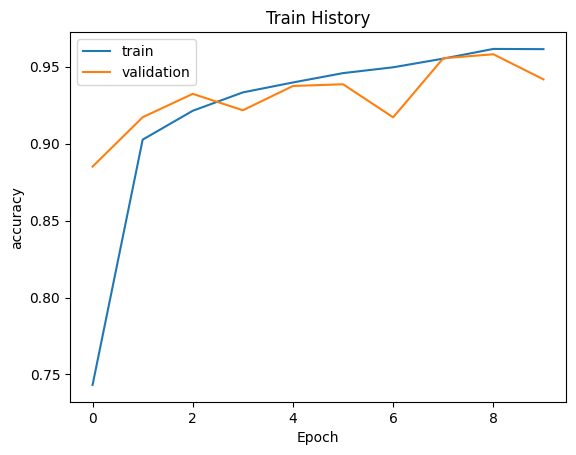

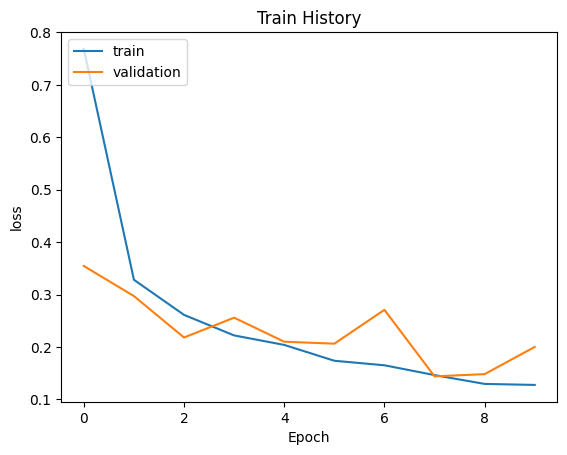

In [24]:
score=M8.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M8,'accuracy','val_accuracy')
show_train_history(train_history_M8,'loss','val_loss')

### **Part C. Your Model**

Based on the Model 1-8, develope a model to improve the classification results. The requirements are
1. Compare three different backborn models.
2. Improve the classification results as much as you can.

# ResNet50

In [15]:
early_stop=tensorflow.keras.callbacks.EarlyStopping(monitor='val_loss', # what is the metric to measure
                          patience=15, # how many epochs to continue running the model after seeing an increase in val_loss
                          restore_best_weights=True) # update the model with the best-seen weights?

reduce_LR=tensorflow.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                          factor=0.1,
                          patience=5) # to make sure early_stop is what stops the model

callback_list=[reduce_LR, early_stop]

# print learning rate each epoch to see if reduce_LR is working as expected
# https://stackoverflow.com/questions/48198031/keras-add-variables-to-progress-bar/48206009#48206009
def get_lr_metric(optimizer):
  def lr(y_true, y_pred):
    return optimizer.learning_rate
  return lr

optimizer=Adam(learning_rate=1e-4)
lr_metric=get_lr_metric(optimizer)

In [16]:
M9=Sequential()

input_shape=X_train.shape[1:]
res_base=resnet50.ResNet50(include_top=False, input_shape=input_shape)
res_base.trainable=True

M9.add(res_base)

M9.add(Flatten())
M9.add(Dropout(0.5))
M9.add(Dense(512, activation='relu'))
M9.add(Dense(num_classes, activation='softmax'))

M9.summary()

M9.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy', lr_metric])

train_datagen=ImageDataGenerator(horizontal_flip=True, vertical_flip=True)
test_datagen=ImageDataGenerator()

train_generator=train_datagen.flow(X_train, y_train, batch_size=batch_size, seed=42)
test_generator=test_datagen.flow(X_test, y_test, batch_size=batch_size, seed=42)

train_history_M9=M9.fit(train_generator, steps_per_epoch=None, epochs=epochs,
            validation_data=test_generator, validation_steps=len(X_test)//batch_size, callbacks=callback_list)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 2, 2, 2048)        23587712  
                                                                 
 flatten_2 (Flatten)         (None, 8192)              0         
                                                                 
 dropout_2 (Dropout)         (None, 8192)              0         
                                                                 
 dense_4 (Dense)             (None, 512)               4194816   
                                                                 
 dense_5 (Dense)             (None, 10)                5130      
                                                                 
Total params: 27787658 (106.00 MB)
Trainable params: 27734538 (105.80 MB)
Non-trainable params: 53120 (207.50 KB)
_________________________________________________________________
Epoch 

Test loss: 0.20673918724060059
Test accuracy: 0.9391111135482788


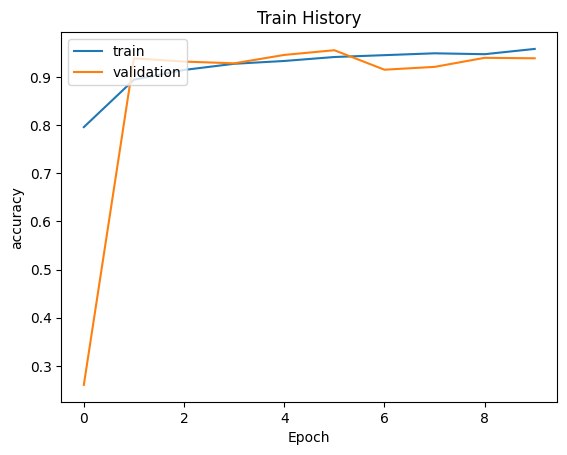

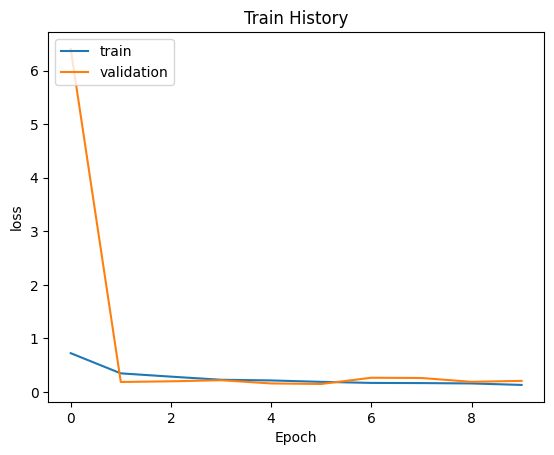

In [17]:
score=M9.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M9,'accuracy','val_accuracy')
show_train_history(train_history_M9,'loss','val_loss')

# DenseNet121

In [12]:
early_stop=tensorflow.keras.callbacks.EarlyStopping(monitor='val_loss', # what is the metric to measure
                          patience=15, # how many epochs to continue running the model after seeing an increase in val_loss
                          restore_best_weights=True) # update the model with the best-seen weights?

reduce_LR=tensorflow.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                          factor=0.1,
                          patience=5) # to make sure early_stop is what stops the model

callback_list=[reduce_LR, early_stop]

# print learning rate each epoch to see if reduce_LR is working as expected
# https://stackoverflow.com/questions/48198031/keras-add-variables-to-progress-bar/48206009#48206009
def get_lr_metric(optimizer):
  def lr(y_true, y_pred):
    return optimizer.learning_rate
  return lr

optimizer=Adam(learning_rate=1e-4)
lr_metric=get_lr_metric(optimizer)

In [13]:
M10=Sequential()

input_shape=X_train.shape[1:]
den_base=tensorflow.keras.applications.DenseNet121(include_top=False, input_shape=input_shape)
den_base.trainable=True

M10.add(den_base)

M10.add(Flatten())
M10.add(Dropout(0.5))
M10.add(Dense(512, activation='relu'))
M10.add(Dense(num_classes, activation='softmax'))

M10.summary()

M10.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy', lr_metric])

train_datagen=ImageDataGenerator(horizontal_flip=True, vertical_flip=True)
test_datagen=ImageDataGenerator()

train_generator=train_datagen.flow(X_train, y_train, batch_size=batch_size, seed=42)
test_generator=test_datagen.flow(X_test, y_test, batch_size=batch_size, seed=42)

train_history_M10=M10.fit(train_generator, steps_per_epoch=None, epochs=epochs,
            validation_data=test_generator, validation_steps=len(X_test)//batch_size, callbacks=callback_list)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 densenet121 (Functional)    (None, 2, 2, 1024)        7037504   
                                                                 
 flatten_1 (Flatten)         (None, 4096)              0         
                                                                 
 dropout_1 (Dropout)         (None, 4096)              0         
                                                                 
 dense_2 (Dense)             (None, 512)               2097664   
                                                                 
 dense_3 (Dense)             (None, 10)                5130      
                                                                 
Total params: 9140298 (34.87 MB)
Trainable params: 9056650 (34.55 MB)
Non-trainable params: 83648 (326.75 KB)
_________________________________________________________________
Epoch 1/10

2025-11-12 00:07:34.855141: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
2025-11-12 00:07:37.368886: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:606] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-11-12 00:07:37.380776: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x77de150 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-12 00:07:37.380794: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2025-11-12 00:07:37.384277: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:255] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-12 00:07:37.463750: I ./tensorflow/compiler/jit/device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of

844/844 [==============================] - 79s 46ms/step - loss: 0.6996 - accuracy: 0.7839 - lr: 1.0000e-04 - val_loss: 0.2451 - val_accuracy: 0.9268 - val_lr: 1.0000e-04
Epoch 2/10
844/844 [==============================] - 31s 36ms/step - loss: 0.3266 - accuracy: 0.8971 - lr: 1.0000e-04 - val_loss: 0.1581 - val_accuracy: 0.9487 - val_lr: 1.0000e-04
Epoch 3/10
844/844 [==============================] - 30s 36ms/step - loss: 0.2597 - accuracy: 0.9167 - lr: 1.0000e-04 - val_loss: 0.1661 - val_accuracy: 0.9485 - val_lr: 1.0000e-04
Epoch 4/10
844/844 [==============================] - 30s 36ms/step - loss: 0.2081 - accuracy: 0.9331 - lr: 1.0000e-04 - val_loss: 0.1914 - val_accuracy: 0.9419 - val_lr: 1.0000e-04
Epoch 5/10
844/844 [==============================] - 30s 36ms/step - loss: 0.1982 - accuracy: 0.9367 - lr: 1.0000e-04 - val_loss: 0.1079 - val_accuracy: 0.9656 - val_lr: 1.0000e-04
Epoch 6/10
844/844 [==============================] - 30s 36ms/step - loss: 0.1546 - accuracy: 0.9507

Test loss: 0.17073363065719604
Test accuracy: 0.9468148350715637


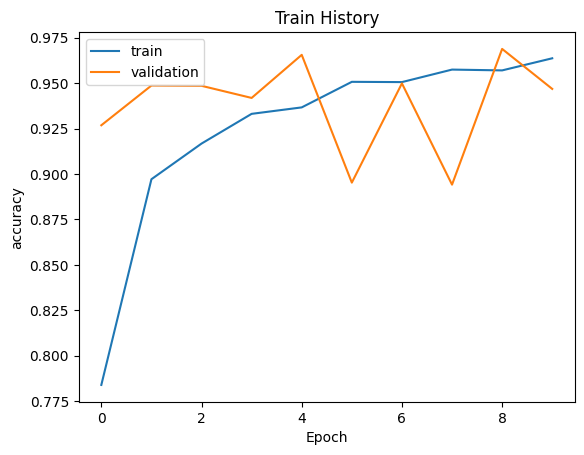

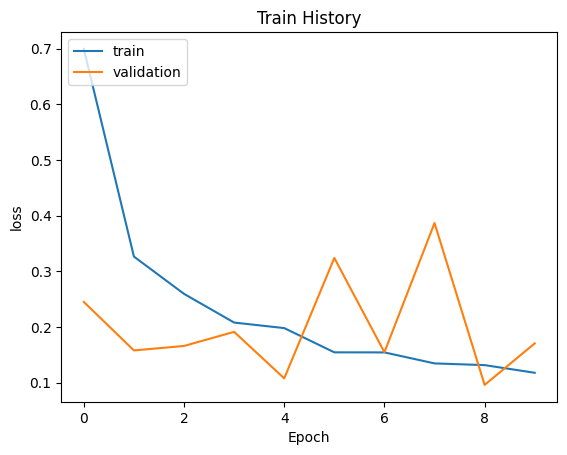

In [14]:
score=M10.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

def show_train_history(train_history,train,validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train','validation'],loc='upper left')
  plt.show()

show_train_history(train_history_M10,'accuracy','val_accuracy')
show_train_history(train_history_M10,'loss','val_loss')